In [1]:
print("hello world")

hello world


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
DATA_PATH = (
    r"D:\adaptive_federated_gnn\data\raw\other datasets\GeneratedLabelledFlows\TrafficLabelling\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found:\n{DATA_PATH}")

print("Dataset found successfully.")

Dataset found successfully.


In [4]:
df = pd.read_csv(
    DATA_PATH,
    encoding="cp1252",
    low_memory=False
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [5]:
df.columns = df.columns.str.strip()

print("Column names cleaned.")

Column names cleaned.


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 286467
Number of columns: 85


In [7]:
df.head()
df.tail()

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
286462,192.168.10.16-199.244.48.55-41926-443-6,192.168.10.16,41926,199.244.48.55,443,6,7/7/2017 3:29,196135,49,57,1331,105841,570,0,27.163265,108.067176,4344,0,1856.859649,972.796621,5.464196e+05,540.444082,1867.952381,7207.469062,53438.0,1.0,196135.0,4086.145833,10366.095180,53521.0,1.0,172901.0,3087.517857,9307.416597,53438.0,2.0,0,0,0,0,1252,1832,249.827925,290.616157,0,4344,1001.607477,1160.591064,1346971.618,0,0,0,1,0,0,0,0,1,1011.056604,27.163265,1856.859649,1252,0,0,0,0,0,0,49,1331,57,105841,29200,61,31,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
286463,192.168.10.16-199.244.48.55-41934-443-6,192.168.10.16,41934,199.244.48.55,443,6,7/7/2017 3:29,378424,49,59,1325,104393,570,0,27.040816,108.095051,2896,0,1769.372881,848.453540,2.793639e+05,285.394161,3536.672897,18326.251010,173388.0,0.0,378424.0,7883.833333,34491.462460,236489.0,2.0,355402.0,6127.620690,27253.356700,196547.0,1.0,0,0,0,0,1264,1896,129.484388,155.909773,0,2896,969.889908,1073.781250,1153006.173,0,0,0,1,0,0,0,0,1,978.870370,27.040816,1769.372881,1264,0,0,0,0,0,0,49,1325,59,104393,29200,61,30,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
286464,192.168.10.16-199.244.48.55-41932-443-6,192.168.10.16,41932,199.244.48.55,443,6,7/7/2017 3:29,161800,70,103,1427,215903,570,0,20.385714,90.746389,4344,0,2096.145631,920.298603,1.343201e+06,1069.221261,940.697674,3947.183709,23268.0,1.0,161800.0,2344.927536,6109.558409,23934.0,2.0,138764.0,1360.431373,5201.981596,32464.0,1.0,0,0,0,0,1732,3304,432.632880,636.588381,0,4344,1249.022989,1244.874147,1549711.641,0,0,0,1,0,0,0,0,1,1256.242775,20.385714,2096.145631,1732,0,0,0,0,0,0,70,1427,103,215903,29200,61,47,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
286465,192.168.10.16-199.244.48.55-41930-443-6,192.168.10.16,41930,199.244.48.55,443,6,7/7/2017 3:29,142864,50,62,1331,110185,570,0,26.620000,107.027727,2896,0,1777.177419,799.911092,7.805745e+05,783.962370,1287.063063,4955.002013,23111.0,1.0,142864.0,2915.591837,7300.372125,23800.0,2.0,119753.0,1963.163934,6025.630847,23826.0,1.0,0,0,0,0,1284,1992,349.983201,433.979169,0,2896,986.867257,1058.110053,1119596.884,0,0,0,1,0,0,0,0,1,995.678571,26.620000,1777.177419,1284,0,0,0,0,0,0,50,1331,62,110185,29200,61,31,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
286466,192.168.10.16-199.244.48.55-41928-443-6,192.168.10.16,41928,199.244.48.55,443,6,7/7/2017 3:29,186928,46,57,1319,100049,570,0,28.673913,111.438085,2896,0,1755.245614,849.040557,5.422837e+05,551.014294,1832.627451,6720.903665,44740.0,-1.0,186928.0,4153.955556,9798.936450,44905.0,4.0,163676.0,2922.785714,8478.478825,44740.0,1.0,0,0,0,0,1180,1832,246.084054,304.930241,0,2896,974.692308,1

In [8]:
print(df.columns.tolist())

['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH 

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 286467 entries, 0 to 286466
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flow ID                      286467 non-null  str    
 1   Source IP                    286467 non-null  str    
 2   Source Port                  286467 non-null  int64  
 3   Destination IP               286467 non-null  str    
 4   Destination Port             286467 non-null  int64  
 5   Protocol                     286467 non-null  int64  
 6   Timestamp                    286467 non-null  str    
 7   Flow Duration                286467 non-null  int64  
 8   Total Fwd Packets            286467 non-null  int64  
 9   Total Backward Packets       286467 non-null  int64  
 10  Total Length of Fwd Packets  286467 non-null  int64  
 11  Total Length of Bwd Packets  286467 non-null  int64  
 12  Fwd Packet Length Max        286467 non-null  int64  
 13  Fwd Packet

In [15]:
df.dtypes

Flow ID                            str
Source IP                          str
Source Port                      int64
Destination IP                     str
Destination Port                 int64
Protocol                         int64
Timestamp                          str
Flow Duration                    int64
Total Fwd Packets                int64
Total Backward Packets           int64
Total Length of Fwd Packets      int64
Total Length of Bwd Packets      int64
Fwd Packet Length Max            int64
Fwd Packet Length Min            int64
Fwd Packet Length Mean         float64
Fwd Packet Length Std          float64
Bwd Packet Length Max            int64
Bwd Packet Length Min            int64
Bwd Packet Length Mean         float64
Bwd Packet Length Std          float64
Flow Bytes/s                   float64
Flow Packets/s                 float64
Flow IAT Mean                  float64
Flow IAT Std                   float64
Flow IAT Max                   float64
Flow IAT Min             

In [14]:
missing_values = df.isnull().sum()

missing_values = missing_values.sort_values(
    ascending=False
)

missing_values.head(20)

Flow Bytes/s                   15
Source IP                       0
Source Port                     0
Destination IP                  0
Flow ID                         0
Destination Port                0
Protocol                        0
Flow Duration                   0
Timestamp                       0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Total Fwd Packets               0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Std           0
Fwd Packet Length Mean          0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
dtype: int64

In [16]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage.head(20)

Flow Bytes/s                   0.005236
Source IP                      0.000000
Source Port                    0.000000
Destination IP                 0.000000
Flow ID                        0.000000
Destination Port               0.000000
Protocol                       0.000000
Flow Duration                  0.000000
Timestamp                      0.000000
Total Backward Packets         0.000000
Total Length of Fwd Packets    0.000000
Total Length of Bwd Packets    0.000000
Total Fwd Packets              0.000000
Fwd Packet Length Max          0.000000
Fwd Packet Length Min          0.000000
Fwd Packet Length Std          0.000000
Fwd Packet Length Mean         0.000000
Bwd Packet Length Max          0.000000
Bwd Packet Length Min          0.000000
Bwd Packet Length Mean         0.000000
dtype: float64

In [17]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 1


In [18]:
label_column = "Label"

if label_column not in df.columns:
    raise KeyError(
        f"Label column not found.\n"
        f"Available columns:\n{df.columns.tolist()}"
    )

print("Label column found.")

Label column found.


In [19]:
label_counts = df[label_column].value_counts()

print(label_counts)

Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64


In [20]:
label_percentages = (
    df[label_column]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(label_percentages)

Label
PortScan    55.48
BENIGN      44.52
Name: proportion, dtype: float64


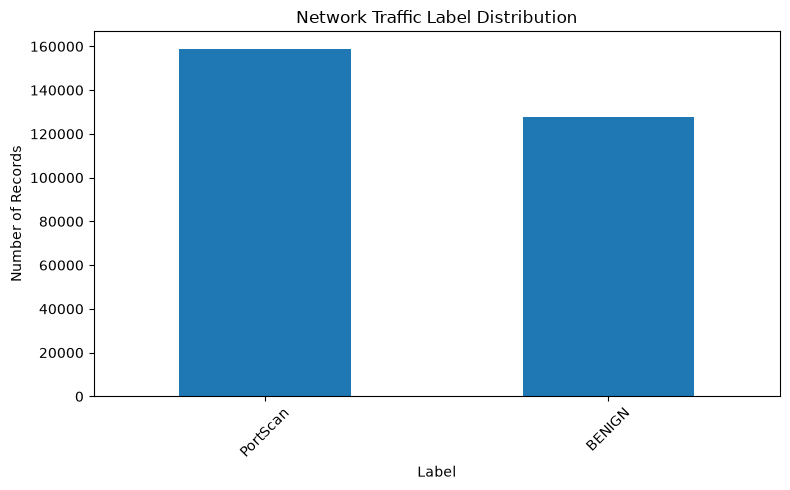

In [21]:
plt.figure(figsize=(8, 5))

df[label_column].value_counts().plot(
    kind="bar"
)

plt.title("Network Traffic Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [22]:
required_columns = [
    "Source IP",
    "Destination IP",
    "Source Port",
    "Destination Port",
    "Protocol",
    "Timestamp",
    "Label"
]

for column in required_columns:
    if column in df.columns:
        print(f"{column}: FOUND")
    else:
        print(f"{column}: NOT FOUND")

Source IP: FOUND
Destination IP: FOUND
Source Port: FOUND
Destination Port: FOUND
Protocol: FOUND
Timestamp: FOUND
Label: FOUND


In [23]:
for column in required_columns:
    if column in df.columns:
        print(f"\n{column}")
        print("Unique values:", df[column].nunique())
        print(df[column].head(10).tolist())


Source IP
Unique values: 3667
['192.168.10.12', '192.168.10.16', '192.168.10.12', '192.168.10.12', '192.168.10.50', '192.168.10.16', '192.168.10.16', '192.168.10.50', '192.168.10.12', '192.168.10.16']

Destination IP
Unique values: 4401
['192.168.10.50', '192.168.10.50', '192.168.10.50', '192.168.10.50', '192.168.10.12', '192.168.10.50', '192.168.10.50', '192.168.10.16', '192.168.10.50', '192.168.10.50']

Source Port
Unique values: 36962
[35396, 60058, 35396, 35398, 22, 60058, 60060, 22, 35398, 60060]

Destination Port
Unique values: 14495
[22, 22, 22, 22, 35396, 22, 22, 60058, 22, 22]

Protocol
Unique values: 3
[6, 6, 6, 6, 6, 6, 6, 6, 6, 6]

Timestamp
Unique values: 150
['7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00', '7/7/2017 1:00']

Label
Unique values: 2
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']


In [24]:
numeric_df = df.select_dtypes(include=np.number)

infinite_values = np.isinf(numeric_df).sum().sum()

print("Infinite values:", infinite_values)

Infinite values: 727


In [25]:
df.describe().T

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Source Port,286467.0,4.393243e+04,1.771390e+04,0.0,37516.000000,49008.000000,56576.000000,6.553500e+04
Destination Port,286467.0,8.044876e+03,1.537858e+04,0.0,80.000000,1110.000000,6881.000000,6.538900e+04
Protocol,286467.0,8.306000e+00,4.481562e+00,0.0,6.000000,6.000000,6.000000,1.700000e+01
Flow Duration,286467.0,5.379331e+06,2.192364e+07,-13.0,44.000000,65.000000,23806.000000,1.199999e+08
Total Fwd Packets,286467.0,3.473283e+00,1.951513e+01,1.0,1.000000,1.000000,2.000000,3.119000e+03
Total Backward Packets,286467.0,3.520500e+00,2.828892e+01,0.0,1.000000,1.000000,2.000000,3.635000e+03
Total Length of Fwd Packets,286467.0,2.334077e+02,1.865524e+03,0.0,0.000000,2.000000,62.000000,2.323490e+05
Total Length of Bwd Packets,286467.0,2.707247e+03,5.097783e+04,0.0,6.000000,6.000000,115.000000,7.150819e+06
Fwd Packet Length Max,286467.0,8.103337e+01,3.277680e+02,0.0,0.000000,2.000000,37.000000,1.392900e+04
Fwd Packet Length Min,286467.0,1.035201e+01,2.423780e+01,0.0,0.000000,2.000000,6.000000,1.472000e+03


In [26]:
os.makedirs("../outputs/day1", exist_ok=True)

summary = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Total missing values",
        "Duplicate rows",
        "Number of labels",
        "Infinite values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        int(df[label_column].nunique()),
        int(infinite_values)
    ]
})

summary

,Metric,Value
0,Number of rows,286467
1,Number of columns,85
2,Total missing values,15
3,Duplicate rows,1
4,Number of labels,2
5,Infinite values,727


In [27]:
summary.to_csv(
    "../outputs/day1/dataset_summary.csv",
    index=False
)

label_counts.to_csv(
    "../outputs/day1/label_distribution.csv"
)

missing_values.to_csv(
    "../outputs/day1/missing_values.csv"
)

print("Day 1 output files saved successfully.")

Day 1 output files saved successfully.


In [28]:
print("Dataset shape:", df.shape)
print("Labels:", df[label_column].unique())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nDay 1 completed successfully.")

Dataset shape: (286467, 85)
Labels: <StringArray>
['BENIGN', 'PortScan']
Length: 2, dtype: str
Missing values: 15
Duplicate rows: 1

Day 1 completed successfully.
